# LightGBM for regression

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train LightGBM to predict the rent price of an apartment. We train with early stopping, then compare the two ways of sampling rows, bagging and GOSS, different numbers of bins for the histograms, and different numbers of leaves for trees with a limited depth. Then, we train with callbacks that print the score, change the learning rate and save checkpoints, save and load the model, and resume the training from a checkpoint. Finally, we compare the two types of feature importance.

LightGBM ships a scikit-learn wrapper, `LGBMRegressor` and `LGBMClassifier`, which fits into scikit-learn pipelines and searches. In this course we use the native API, `lgb.train` with a `Dataset`, because it exposes the full feature set of the library.

In [1]:
import pathlib
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [3]:
# LightGBM splits on categories directly, so we keep them as pandas categories instead of integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].astype("category")

# LightGBM takes missing values, so we leave NaN as it is

df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

In [5]:
# the mean rent price
y_train.mean(), y_test.mean()

(np.float64(1527.515742929929), np.float64(1526.5632805716957))

### Prepare the data for LightGBM

LightGBM trains on a `Dataset`, which holds the data already cut into bins. The test set takes the train set as `reference`, so that both use the same bins.

We set `free_raw_data=False`, so that the datasets keep the raw data and LightGBM can rebuild the bins when we change `max_bin`.

In [6]:
train_set = lgb.Dataset(X_train, y_train, free_raw_data=False)
test_set = lgb.Dataset(X_test, y_test, reference=train_set, free_raw_data=False)

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

In [7]:
params = {
    # learning task
    "objective": "regression",   # squared error
    "metric": "rmse",

    # sampling
    "data_sample_strategy": "bagging",
    "bagging_fraction": 1.0,     # share of the rows for each tree
    "bagging_freq": 0,           # 0 means no bagging
    "feature_fraction": 1.0,     # share of the features for each tree

    # feature processing
    "enable_bundle": True,       # bundles features that are never nonzero together; the trees stay the same
    "max_bin": 255,              # maximum number of bins per feature

    # tree structure and algorithm
    "boosting": "gbdt",
    "learning_rate": 0.1,
    "early_stopping_round": 50,  # the early-stopping rule, the default 0 means no early stopping
    "num_leaves": 31,            # the main limit of a leaf-wise tree
    "max_depth": -1,             # no limit
    "min_data_in_leaf": 20,

    # regularization
    "min_gain_to_split": 0.0,
    "lambda_l2": 0.0,
    "lambda_l1": 0.0,

    # categorical features
    "max_cat_to_onehot": 4,      # up to this many categories, one category against the rest
    "max_cat_threshold": 32,
    "min_data_per_group": 100,

    # additional important parameters
    "device_type": "cpu",
    "seed": 0,
    "num_threads": 4,            # fixed, so that the training times are comparable
    "verbose": -1,               # keep the warnings out of the output
}

We let the model grow up to 2000 trees and stop when the rmse in the test set has not improved for 50 rounds. We set this rule with `early_stopping_round` in the parameters, and `lgb.train` adds the early-stopping callback by itself. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
evals_result = {}

booster = lgb.train(
    params,
    train_set,
    num_boost_round=2000,
    valid_sets=[train_set, test_set],
    valid_names=["train", "test"],
    callbacks=[
        lgb.record_evaluation(evals_result),
        lgb.log_evaluation(period=50),
    ],
)

booster.best_iteration, booster.num_trees()

[50]	train's rmse: 435.672	test's rmse: 453.895


[100]	train's rmse: 391.148	test's rmse: 436.334
[150]	train's rmse: 367.195	test's rmse: 427.709


[200]	train's rmse: 351.382	test's rmse: 423.951
[250]	train's rmse: 336.877	test's rmse: 421.321


[300]	train's rmse: 326.106	test's rmse: 419.861
[350]	train's rmse: 316.803	test's rmse: 418.15


[400]	train's rmse: 309.228	test's rmse: 416.619
[450]	train's rmse: 300.642	test's rmse: 416.996


[500]	train's rmse: 292.797	test's rmse: 415.074
[550]	train's rmse: 285.069	test's rmse: 414.958


(533, 533)

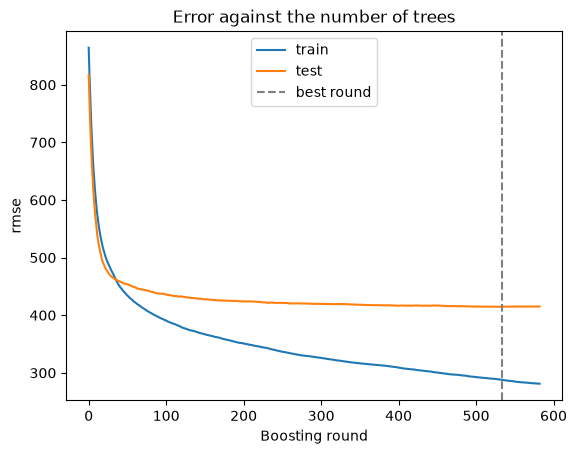

In [9]:
plt.plot(evals_result["train"]["rmse"], label="train")
plt.plot(evals_result["test"]["rmse"], label="test")
plt.axvline(booster.best_iteration, color="grey", linestyle="dashed", label="best round")
plt.xlabel("Boosting round")
plt.ylabel("rmse")
plt.title("Error against the number of trees")
plt.legend()
plt.show()

The test rmse reached its lowest value at round 533, and early stopping trained 50 more rounds before it gave up. `lgb.train` drops those extra rounds and returns a booster with 533 trees, because with the default `keep_training_booster=False` it rebuilds the booster from a copy that stops at the best round.

In [10]:
def evaluate(model, X_train, y_train, X_test, y_test):
    for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        rmse = root_mean_squared_error(y, model.predict(X))
        r2 = r2_score(y, model.predict(X))
        print(f"{name} rmse: {rmse:.2f}, r2: {r2:.4f}")


evaluate(booster, X_train, y_train, X_test, y_test)

train rmse: 288.15, r2: 0.9014


test rmse: 414.53, r2: 0.7727


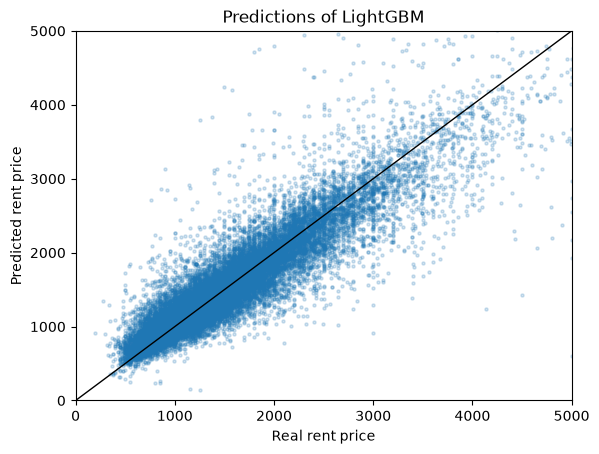

In [11]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = booster.predict(X_test)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of LightGBM")
plt.show()

The model fits the train set better than the test set, with an rmse of 288 against 415, and its test rmse is much lower than the 522 of the gradient boosting machine with the default parameters in the previous section.

Let's now change one hyperparameter at a time to understand what is going on.

Below, every setting trains the number of trees that early stopping found, and we remove `early_stopping_round` from the parameters, so that differences in time come from the setting and not from the number of trees, and the scores show what each setting reaches with that number of trees.

In [12]:
def timed_train(params, train_set, num_rounds):
    start = time.perf_counter()
    model = lgb.train(params, train_set, num_boost_round=num_rounds)
    return model, time.perf_counter() - start

In [13]:
def scores(model, X_train, y_train, X_test, y_test):
    predictions = model.predict(X_test)
    return {
        "train rmse": root_mean_squared_error(y_train, model.predict(X_train)),
        "test rmse": root_mean_squared_error(y_test, predictions),
        "test r2": r2_score(y_test, predictions),
    }

In [14]:
num_rounds = booster.best_iteration
params.pop("early_stopping_round")

num_rounds

533

### Row sampling: bagging and GOSS

We saw in the lecture on gradient-based one-side sampling that GOSS keeps the `top_rate` share of the rows with the largest absolute gradients, draws another `other_rate` share of all the rows from the rest, and scales up the drawn rows, while bagging gives every row the same chance. Both build each tree on fewer rows, so they should train faster.

> **Note:** Since LightGBM 4.0, GOSS is a row sampling strategy, set with `data_sample_strategy="goss"`. The older `boosting="goss"` still works, but LightGBM warns and translates it into the new setting.

The times depend on the machine, so we should read them relative to each other.

In [15]:
sampling = {
    "no sampling": {},
    "bagging 0.8": {"bagging_fraction": 0.8, "bagging_freq": 1},
    "goss 0.2 / 0.1": {"data_sample_strategy": "goss", "top_rate": 0.2, "other_rate": 0.1},
    "goss 0.4 / 0.2": {"data_sample_strategy": "goss", "top_rate": 0.4, "other_rate": 0.2},
}

In [16]:
results = {}
for name, setting in sampling.items():
    model, seconds = timed_train({**params, **setting}, train_set, num_rounds)
    results[name] = {"seconds": seconds, **scores(model, X_train, y_train, X_test, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train rmse,test rmse,test r2
no sampling,1.4628,288.1534,414.5300,0.7727
bagging 0.8,2.3772,292.9405,412.1638,0.7753
goss 0.2 / 0.1,2.7836,316.7673,417.9031,0.7690
goss 0.4 / 0.2,2.0293,306.4868,407.5219,0.7804


On this data, none of the sampling settings trains faster than no sampling, and GOSS with 0.2 / 0.1 is the slowest.

The sampling raises the rmse in the train set in every case, from 288 to between 293 and 317, because each tree sees only part of the data. With the same 533 trees, GOSS with 0.4 / 0.2 lowers the rmse in the test set from 415 to 408, while bagging changes it by only a few units and GOSS with 0.2 / 0.1 raises it to 418.

### Histogram resolution

We saw in the lecture on the histogram-based algorithm that LightGBM cuts each feature into at most `max_bin` bins before training, and only tries the bin edges as split points. Fewer bins mean fewer split candidates, so the scan of each histogram is shorter, but the split points are coarser.

In [17]:
results = {}
for max_bin in [15, 63, 255, 1023]:
    # LightGBM rebuilds the bins of train_set from its raw data, inside the timer for every setting
    model, seconds = timed_train({**params, "max_bin": max_bin}, train_set, num_rounds)
    results[max_bin] = {"seconds": seconds, **scores(model, X_train, y_train, X_test, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train rmse,test rmse,test r2
15,1.6195,335.0321,427.7031,0.7581
63,1.5809,304.6121,429.2534,0.7563
255,1.5858,288.1534,414.5300,0.7727
1023,2.0496,283.5916,411.1297,0.7765


Fewer bins do not make the training faster here. With the same number of trees, 15 and 63 bins raise the rmse in the test set to 428 and 429, from 415 with the default of 255, and 1023 bins lower it a little, to 411, but train slower.

### Leaf-wise growth under a depth limit

We saw in the lecture on leaf-wise tree growth that LightGBM always splits the leaf with the largest gain, so `num_leaves` is the main limit of its trees, and `max_depth` is unlimited by default. A tree of depth 6 has at most 64 leaves, so a tree can reach 64 leaves only if it is the full tree of depth 6, the tree that a level-wise algorithm grows when every leaf can be split.

We fix `max_depth=6`, train with 4 to 64 leaves, and count the leaves that the trees actually have.

In [18]:
def mean_leaves(model):
    # the leaves are the nodes without a split feature
    trees = model.trees_to_dataframe()
    return trees["split_feature"].isna().groupby(trees["tree_index"]).sum().mean()

In [19]:
results = {}
for num_leaves in [4, 8, 16, 32, 64]:
    model = lgb.train({**params, "max_depth": 6, "num_leaves": num_leaves}, train_set, num_rounds)
    results[num_leaves] = {
        "train rmse": root_mean_squared_error(y_train, model.predict(X_train)),
        "test rmse": root_mean_squared_error(y_test, model.predict(X_test)),
        "leaves per tree": mean_leaves(model),
    }

leaves_results = pd.DataFrame(results).T
leaves_results.round(1)

,train rmse,test rmse,leaves per tree
4,441.9,449.1,4.0
8,384.8,428.7,8.0
16,344.6,426.1,15.9
32,321.5,425.5,27.2
64,324.0,425.1,28.7


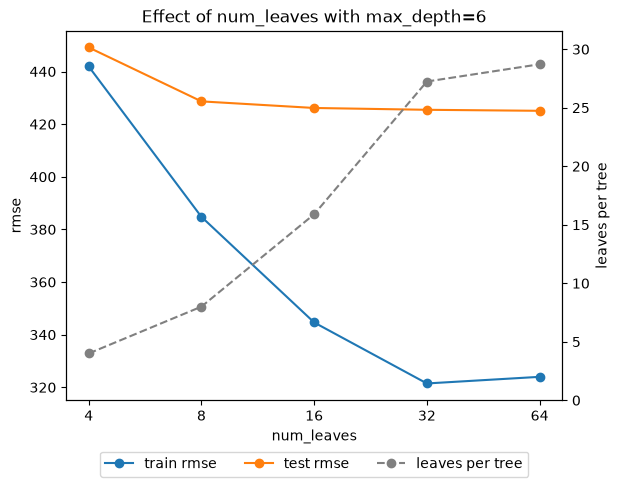

In [20]:
left = plt.gca()
plt.plot(leaves_results.index, leaves_results["train rmse"], marker="o", label="train rmse")
plt.plot(leaves_results.index, leaves_results["test rmse"], marker="o", label="test rmse")
plt.xscale("log", base=2)
plt.xticks(leaves_results.index, leaves_results.index)
plt.xlabel("num_leaves")
plt.ylabel("rmse")
right = plt.twinx()
plt.plot(leaves_results.index, leaves_results["leaves per tree"], marker="o", color="grey", linestyle="dashed", label="leaves per tree")
# the leaves start at 0, so that small changes do not look large
plt.ylim(0, 1.1 * leaves_results["leaves per tree"].max())
plt.ylabel("leaves per tree")
# one legend for the lines of both axes, below the plot so that it hides no point
plt.legend(handles=left.get_lines() + right.get_lines(), loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=3)
plt.title("Effect of num_leaves with max_depth=6")
plt.show()

Up to 8 leaves, every tree reaches the `num_leaves` that we allow, and with the same 533 trees the test rmse falls from 449 with 4 leaves to 426 with 16. With 64 leaves, the trees only have 29 on average, because almost all the leaves that stop before depth 6 hold fewer than 40 apartments, too few to be split under a `min_data_in_leaf` of 20, so the test rmse stays at about 425 from 16 leaves on.

That is clearly higher than the 415 of the default model, whose 31 leaves have no depth limit, and more than half of them are deeper than 6. On this data, the leaf-wise trees gain from growing some branches deeper than 6 levels.

## Callbacks and model IO

### Callbacks

In LightGBM, a callback is a function that `lgb.train` calls before or after every round with an `env` object, which holds the model, the index of the round and, after the round, the evaluation results. The printed log and the recorded curve come from the built-in callbacks `log_evaluation` and `record_evaluation`, which run only when we pass them in `callbacks`.

Here, we write one that prints the test rmse every 50 rounds and saves the model at the same time, and combine it with the built-in `reset_parameter`, which sets the learning rate of each round from a function. `reset_parameter` runs before each round, and the other callbacks run after it. We train with the same early stopping as before.

In [21]:
checkpoints = pathlib.Path("checkpoints") / "regression"
checkpoints.mkdir(parents=True, exist_ok=True)

# remove the checkpoints of an earlier run
for path in checkpoints.glob("*.txt"):
    path.unlink()


def print_and_save(env):
    # we skip round 0, whose model has a single tree
    if env.iteration > 0 and env.iteration % 50 == 0:
        rmse = env.evaluation_result_list[0].metric_value
        print(f"round {env.iteration}: test rmse {rmse:.2f}")
        env.model.save_model(checkpoints / f"checkpoint_{env.iteration}.txt")

In [22]:
scheduled_result = {}

scheduled = lgb.train(
    {**params, "early_stopping_round": 50},
    train_set,
    num_boost_round=2000,
    valid_sets=[test_set],
    valid_names=["test"],
    callbacks=[
        print_and_save,
        lgb.reset_parameter(learning_rate=lambda round: 0.1 * 0.999 ** round),
        lgb.record_evaluation(scheduled_result),
    ],
)

scheduled.best_iteration, scheduled.num_trees()

round 50: test rmse 455.08


round 100: test rmse 435.44
round 150: test rmse 427.59


round 200: test rmse 424.39
round 250: test rmse 421.88


round 300: test rmse 420.34
round 350: test rmse 418.42


round 400: test rmse 418.11
round 450: test rmse 417.45


...

round 600: test rmse 414.71
round 650: test rmse 414.18


round 700: test rmse 414.11
round 750: test rmse 413.48


round 800: test rmse 413.25
round 850: test rmse 412.61


round 900: test rmse 412.61


(865, 865)

In [23]:
evaluate(scheduled, X_train, y_train, X_test, y_test)

train rmse: 280.36, r2: 0.9067


test rmse: 412.44, r2: 0.7750


With the learning rate shrinking slowly, from 0.1 to about 0.04 at round 900, the test rmse keeps improving for longer than with a constant learning rate, and early stopping ends the run with its best round at 865. The test rmse ends a little lower than the one of the default model, 412 against 415, but the run needs 865 trees instead of 533.

The number in the file name is `env.iteration`, the index of the round, which counts from 0, so `checkpoint_50.txt` holds 51 trees.

In [24]:
# sort by round number, not alphabetically
[path.name for path in sorted(checkpoints.iterdir(), key=lambda path: int(path.stem.split("_")[1]))]

['checkpoint_50.txt',
 'checkpoint_100.txt',
 'checkpoint_150.txt',
 'checkpoint_200.txt',
 'checkpoint_250.txt',
 'checkpoint_300.txt',
 'checkpoint_350.txt',
 'checkpoint_400.txt',
 'checkpoint_450.txt',
 'checkpoint_500.txt',
 'checkpoint_550.txt',
 'checkpoint_600.txt',
 'checkpoint_650.txt',
 'checkpoint_700.txt',
 'checkpoint_750.txt',
 'checkpoint_800.txt',
 'checkpoint_850.txt',
 'checkpoint_900.txt']

### Save and load the model

We save the model in LightGBM's text format, which holds the trees and the categories of each categorical feature, and load it into a new booster.

In [25]:
booster.save_model("lightgbm-regression.txt")
loaded = lgb.Booster(model_file="lightgbm-regression.txt")

np.array_equal(booster.predict(X_test), loaded.predict(X_test))

True

### Continue the training

Say that the training with the callbacks had been interrupted shortly after round 50. Then its last checkpoint is `checkpoint_50.txt`, and there is no need to start again: we load the checkpoint, pass it to `init_model`, and LightGBM adds new trees on top of the ones that it already has. We add 100 trees with a constant learning rate of 0.05.

LightGBM computes the predictions of the checkpoint for every row and stores them in the datasets as the starting point of the new trees, so we give it fresh datasets and leave `train_set` and `test_set` as they are.

In [26]:
loaded = lgb.Booster(model_file=checkpoints / "checkpoint_50.txt")

loaded.num_trees()

51

In [27]:
continue_train_set = lgb.Dataset(X_train, y_train)
continue_test_set = lgb.Dataset(X_test, y_test, reference=continue_train_set)

continued = lgb.train(
    {**params, "learning_rate": 0.05},
    continue_train_set,
    num_boost_round=100,
    valid_sets=[continue_test_set],
    valid_names=["test"],
    init_model=loaded,
    callbacks=[lgb.log_evaluation(period=25)],
)

print(f"trees before: {loaded.num_trees()}, trees after: {continued.num_trees()}")

[75]	test's rmse: 447.475
[100]	test's rmse: 441.298
[125]	test's rmse: 437.609


[150]	test's rmse: 434.394
trees before: 51, trees after: 151


In [28]:
evaluate(continued, X_train, y_train, X_test, y_test)

train rmse: 391.60, r2: 0.8180
test rmse: 434.26, r2: 0.7506


Starting from the 51 trees of the checkpoint, the 100 new trees with a learning rate of 0.05 bring the test rmse down from 455 at round 50 to 434, which is still well above the 415 of the default model with its 533 trees.

## Feature importance

We saw in the lecture on feature importance that XGBoost summarizes the splits of each feature in three ways: weight, gain and cover. LightGBM offers two types. The type `split` counts the splits that use the feature, like XGBoost's weight, and the type `gain` adds up the gain of those splits, like XGBoost's total gain rather than its average gain. LightGBM has no cover. We plot each type separately, with the 15 most important features.

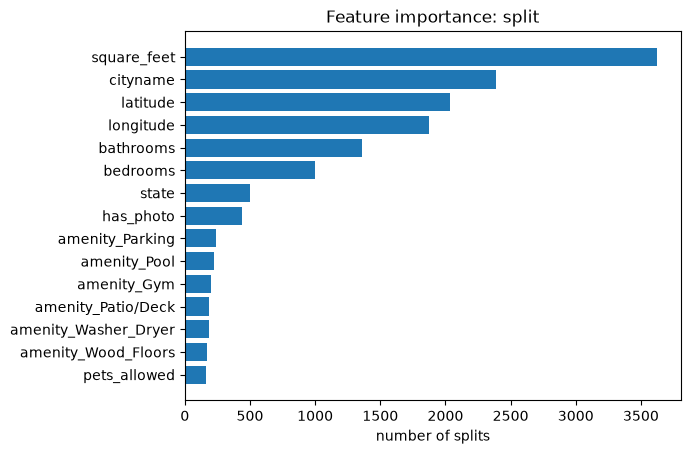

In [29]:
split = pd.Series(
    booster.feature_importance(importance_type="split"),
    index=booster.feature_name(),
).sort_values(ascending=False)

# the 15 most important features, the most important on top
top = split.head(15)
plt.barh(top.index[::-1], top.values[::-1])
plt.xlabel("number of splits")
plt.title("Feature importance: split")
plt.show()

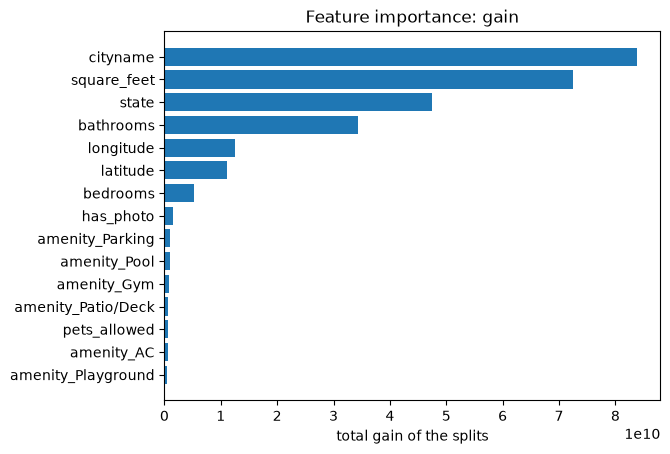

In [30]:
gain = pd.Series(
    booster.feature_importance(importance_type="gain"),
    index=booster.feature_name(),
).sort_values(ascending=False)

# the 15 most important features, the most important on top
top = gain.head(15)
plt.barh(top.index[::-1], top.values[::-1])
plt.xlabel("total gain of the splits")
plt.title("Feature importance: gain")
plt.show()

The two charts agree on the seven features at the top, the location of the apartment (`cityname`, `state`, `latitude`, `longitude`) and its size (`square_feet`, `bathrooms`, `bedrooms`), but not on their order. By split, `square_feet`, `cityname` and `latitude` come first, because variables with many values or categories offer many places to split. By gain, `cityname`, `square_feet` and `state` come first: `state` is only seventh by split, but its few splits reduce the error a lot.